In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 从CSV文件中读取数据
data = pd.read_csv('single_party/approxmax_pool2d_runtime_cuda.csv')
data_origin = pd.read_csv('single_party/func_benchmarks_comm_cuda.csv')
# print(data)
# 提取需要的列数据
functions = data['function']
runtime_1 = data['runtime'] 
runtime_crypten_1 = data['runtime crypten']
runtime_crypten_comm_1 = data['runtime crypten comm']

functions_origin = data_origin['function']
runtime_1_origin = data_origin['runtime'] 
runtime_crypten_1_origin = data_origin['runtime crypten']
runtime_crypten_comm_1_origin = data_origin['runtime crypten comm'] 

print(runtime_1)
print(runtime_crypten_1)
print(runtime_crypten_comm_1)

print(runtime_1_origin[19])
print(runtime_crypten_1_origin[19])
print(runtime_crypten_comm_1_origin[19])

# # 绘制柱形图
# bar_width = 0.35
# index = range(len(functions))

# plt.bar(index, runtime_1, bar_width, label='runtime pytorch')
# plt.bar([i + bar_width for i in index], runtime_crypten_1, bar_width, label='runtime crypten')

# # 设置横坐标刻度和标签
# plt.xticks([i + bar_width/2 for i in index], functions, rotation='vertical')

# # 添加图例
# plt.legend()

# # 添加标题和标签
# plt.title('Runtime Comparison')
# plt.xlabel('functions')
# plt.ylabel('Runtime(s)')

# # 保存
# plt.savefig('img/Runtime Comparison in cpu.png')

# # 显示图形
# plt.show()


0    0.000015
Name: runtime, dtype: float64
0    0.025812
Name: runtime crypten, dtype: float64
0    0.0
Name: runtime crypten comm, dtype: float64
1.4558499970007688e-05
0.1550412489999928
0.0


In [3]:
# 从CSV文件中读取数据
data = pd.read_csv('multi_parties/2/approxmax_pool2d_runtime_cuda.csv')
runtime = []
runtime_crypten = []
runtime_crypten_comm = []
runtime.append(runtime_1)
runtime_crypten.append(runtime_crypten_1)
runtime_crypten_comm.append(runtime_crypten_comm_1)
                            
for i in range(2,9):
    path = 'multi_parties/'+ str(i) +'/approxmax_pool2d_runtime_cuda.csv'
    data = pd.read_csv(path)
    runtime.append(data['runtime'])
    runtime_crypten.append(data['runtime crypten'])
    runtime_crypten_comm.append(data['runtime crypten comm'])

print(runtime_crypten)

[0    0.025812
Name: runtime crypten, dtype: float64, 0    0.035792
Name: runtime crypten, dtype: float64, 0    0.096127
Name: runtime crypten, dtype: float64, 0    0.122933
Name: runtime crypten, dtype: float64, 0    0.154638
Name: runtime crypten, dtype: float64, 0    0.182992
Name: runtime crypten, dtype: float64, 0    0.222991
Name: runtime crypten, dtype: float64, 0    0.277066
Name: runtime crypten, dtype: float64]


In [4]:
# 从CSV文件中读取数据
data_origin = pd.read_csv('multi_parties/2/func_benchmarks_comm_cuda.csv')
runtime_crypten_comm_origin = []
runtime_crypten_origin = []
runtime_crypten_comm_origin.append(runtime_crypten_comm_1_origin)
runtime_crypten_origin.append(runtime_crypten_1_origin)
for i in range(2,9):
    path = 'multi_parties/'+ str(i) +'/func_benchmarks_comm_cuda.csv'
    data_origin = pd.read_csv(path)
    runtime_crypten_comm_origin.append(data_origin['runtime crypten comm'])
    runtime_crypten_origin.append(data_origin['runtime crypten'])

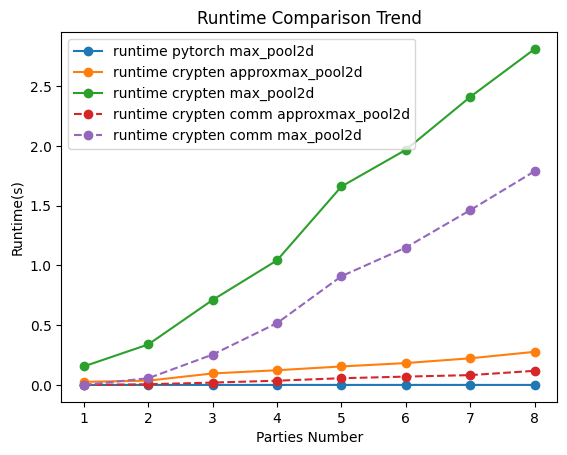

In [7]:
x = list(range(1,9))
y = []
for ele in runtime:
    y.append(ele)
plt.plot(x,y,label='runtime pytorch '+functions_origin[19],marker='o')
    
y_crypten = []
for ele in runtime_crypten:
    y_crypten.append(ele)
plt.plot(x,y_crypten,label='runtime crypten '+functions[0],marker='o')

y_crypten_origin = []
for ele in runtime_crypten_origin:
    y_crypten_origin.append(ele[19])
plt.plot(x,y_crypten_origin,label='runtime crypten '+functions_origin[19],marker='o')

y_crypten_comm = []
for ele in runtime_crypten_comm:
    y_crypten_comm.append(ele)
plt.plot(x,y_crypten_comm,label='runtime crypten comm '+functions[0],linestyle='dashed',marker='o')

y_crypten_comm_origin = []
for ele in runtime_crypten_comm_origin:
    y_crypten_comm_origin.append(ele[19])
plt.plot(x,y_crypten_comm_origin,label='runtime crypten comm '+functions_origin[19],linestyle='dashed',marker='o')
    
# 添加图例
plt.legend()

# 添加标题和标签
plt.title('Runtime Comparison Trend')
plt.xlabel('Parties Number')
plt.ylabel('Runtime(s)')
    
# 保存
plt.savefig('img/Runtime Comparison Trend for ' + functions[0] + ' in gpu.png')
    
plt.show()